# Breast Cancer Wisconsin (Diagnostic): clasificación de tumores

Clasificación de tumores de mama como **benignos (B)** o **malignos (M)** a partir de 30 características numéricas calculadas sobre imágenes digitalizadas de aspirados con aguja fina. Práctica del Diplomado de Business Analytics y Data Science.

**Datos:** *Breast Cancer Wisconsin (Diagnostic)*, disponible en el repositorio UCI Machine Learning Repository (569 registros).

**Contenido:** Análisis exploratorio, preprocesamiento (estandarización y PCA), modelos (Regresión Logística, Árbol de Decisión y Random Forest), importancia de las variables y conclusiones.

In [1]:
## Ver la Tabla y sus Datos
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from matplotlib.patches import Patch

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

os.makedirs("../images", exist_ok=True)

df = pd.read_csv("../data/data.csv")
df

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,NaN
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,NaN
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,NaN
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,NaN


In [2]:
## Ya habiendo visto la tabla y sus datos, procedo a limpiar los que considero que no me aportan a mi análisis como el id y unnamed:32.
df = df.drop(columns=["Unnamed: 32", "id"], errors="ignore")

# También hago un análisis estadístico rápido para entender la enorme cantidad de datos que tengo en mi dataset de forma resumida.
display(df.describe())
display(Markdown("A partir del análisis estadístico descriptivo podemos observar que el dataset contiene 569 registros y no presenta valores faltantes, ya que todas las variables muestran la misma cantidad de observaciones (`count = 569`). Además, las variables presentan escalas muy diferentes entre sí. Por ejemplo, variables como `area_mean` manejan valores promedio superiores a 600, mientras que variables como `smoothness_mean` poseen valores cercanos a 0.09. Esto puede ser un problema ante la diferencia abismal entre variables y por lo tanto necesitaremos estandarizar estos datos antes de entrenar los modelos. También se identificaron posibles valores atípicos (outliers). Un ejemplo claro se observa en la variable `area_worst`, donde el percentil 75% tiene un valor aproximado de 1084, mientras que el valor máximo alcanza 4254. Esto significa que la mayoría de los tumores poseen áreas considerablemente menores, pero existen algunos casos extremadamente grandes en comparación con el comportamiento general del dataset. Finalmente, varias variables relacionadas con el tamaño y la forma de los tumores, como `radius`, `perimeter` y `area`, presentan comportamientos estadísticos similares, lo cual sugiere una posible correlación entre ellas."))

# Y por último, vemos la cantidad de tumores malignos y benignos diagnosticados para evaluar el balance del dataset para la variable de "diagnosis".
# También lo hago porcentaje para entender mejor este balance cuando lo interprete el modelo.
print(df["diagnosis"].value_counts())
porcentajes = (df["diagnosis"].value_counts(normalize=True)*100).round(1)
print(porcentajes.astype(str) + "%")
display(Markdown("El resultado de 62.7% de tumores benignos y 37.3% de tumores malignos representa un balance poco ideal pero no extremo, que permite entrenar los modelos sin un sesgo excesivo hacia una sola clase."))

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


A partir del análisis estadístico descriptivo podemos observar que el dataset contiene 569 registros y no presenta valores faltantes, ya que todas las variables muestran la misma cantidad de observaciones (`count = 569`). Además, las variables presentan escalas muy diferentes entre sí. Por ejemplo, variables como `area_mean` manejan valores promedio superiores a 600, mientras que variables como `smoothness_mean` poseen valores cercanos a 0.09. Esto puede ser un problema ante la diferencia abismal entre variables y por lo tanto necesitaremos estandarizar estos datos antes de entrenar los modelos. También se identificaron posibles valores atípicos (outliers). Un ejemplo claro se observa en la variable `area_worst`, donde el percentil 75% tiene un valor aproximado de 1084, mientras que el valor máximo alcanza 4254. Esto significa que la mayoría de los tumores poseen áreas considerablemente menores, pero existen algunos casos extremadamente grandes en comparación con el comportamiento general del dataset. Finalmente, varias variables relacionadas con el tamaño y la forma de los tumores, como `radius`, `perimeter` y `area`, presentan comportamientos estadísticos similares, lo cual sugiere una posible correlación entre ellas.

diagnosis
B    357
M    212
Name: count, dtype: int64
diagnosis
B    62.7%
M    37.3%
Name: proportion, dtype: str


El resultado de 62.7% de tumores benignos y 37.3% de tumores malignos representa un balance poco ideal pero no extremo, que permite entrenar los modelos sin un sesgo excesivo hacia una sola clase.

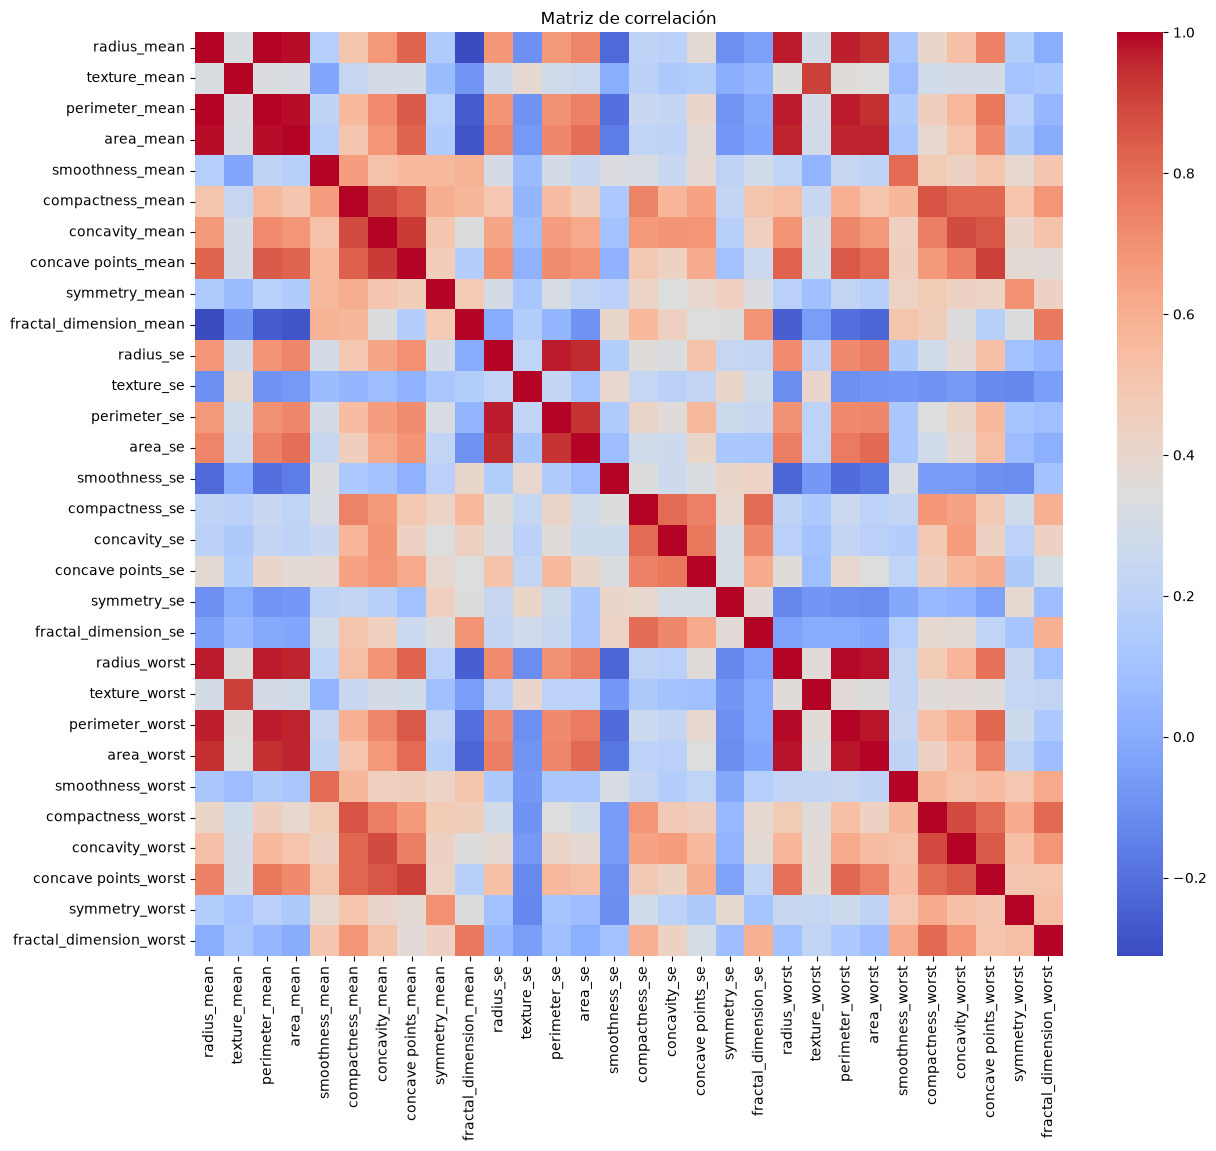

Basado en los resultados que presenta el Heatmap, podemos notar que varias variables presentan una fuerte correlación en base a su interpretación.

Grupo,Variables fuertemente correlacionadas,Interpretación
Tamaño del tumor,"radius_mean, perimeter_mean, area_mean",Describen dimensiones físicas similares del tumor
Tamaño del tumor (worst),"radius_worst, perimeter_worst, area_worst",Representan dimensiones máximas del tumor
Irregularidad del tumor,"compactness_mean, concavity_mean, concave points_mean",Describen deformaciones e irregularidades celulares
Irregularidad del tumor (worst),"compactness_worst, concavity_worst, concave points_worst",Representan irregularidades más extremas
Variabilidad de tamaño (_se),"radius_se, perimeter_se, area_se",Variaciones relacionadas entre medidas de tamaño
Correlación más débil (entre sí),"texture_mean, symmetry_mean, fractal_dimension_mean",Variables más independientes entre sí


In [3]:
# Ante mi conclusión anterior de que habían variables muy correlacionadas, hago un heatmap para saber qué variables están
# relacionadas entre sí y qué tan fuerte es esa relación.

plt.figure(figsize=(14,12))
sns.heatmap(df.corr(numeric_only=True),
            cmap="coolwarm")
plt.title("Matriz de correlación")
plt.savefig("../images/matriz_correlacion.png", dpi=150, bbox_inches="tight")
plt.show()
display(Markdown("Basado en los resultados que presenta el Heatmap, podemos notar que varias variables presentan una fuerte correlación en base a su interpretación."))
correlaciones = pd.DataFrame({
    "Grupo":
        ["Tamaño del tumor",
        "Tamaño del tumor (worst)",
        "Irregularidad del tumor",
        "Irregularidad del tumor (worst)",
        "Variabilidad de tamaño (_se)",
        "Correlación más débil (entre sí)"],
    
    "Variables fuertemente correlacionadas":
        ["radius_mean, perimeter_mean, area_mean",
        "radius_worst, perimeter_worst, area_worst",
        "compactness_mean, concavity_mean, concave points_mean",
        "compactness_worst, concavity_worst, concave points_worst",
        "radius_se, perimeter_se, area_se",
        "texture_mean, symmetry_mean, fractal_dimension_mean"],
    
    "Interpretación":
        ["Describen dimensiones físicas similares del tumor",
        "Representan dimensiones máximas del tumor",
        "Describen deformaciones e irregularidades celulares",
        "Representan irregularidades más extremas",
        "Variaciones relacionadas entre medidas de tamaño",
        "Variables más independientes entre sí"]})

pd.set_option('display.max_colwidth', None)

display(correlaciones.style.hide(axis="index"))

In [4]:
# Después de realizar un análisis exploratorio de los datos del dataset, puedo comenzar a procesar estos datos con un mejor entendimiento.
# Hago un pre-procesamiento para el Machinelearning
from sklearn.model_selection import train_test_split

X = df.drop("diagnosis", axis=1)
y = df["diagnosis"]

# Convierto los textos a números para el algoritmo (M = 1: maligno, la clase positiva; B = 0: benigno).
y = y.map({"M":1, "B":0})

# Divido mi dataset en características para entrenar, probar y respuestas reales de entrenamiento y respuestas reales de prueba.
# Escojo una proporción de 20% para la prueba al ser lo más común y aleatoriedad de 42.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Debido a las diferencias de escala identificadas previamente en el análisis exploratorio, se aplica estandarización para evitar que variables
# con magnitudes mayores dominen el modelo.

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [5]:
# Debido a la alta correlación observada entre múltiples variables (cuadro de más arriba), decido aplicar PCA para reducir
# dimensionalidad y disminuir redundancia en los datos.


# Creo el PCA conservando el 95% de la varianza y así conserve este porcentaje de la información original.
pca = PCA(n_components=0.95)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Dimensiones originales:", X_train_scaled.shape)
print("Dimensiones después de PCA:", X_train_pca.shape)
print(f"Varianza conservada: {pca.explained_variance_ratio_.sum() * 100:.1f}%")
# Reduje de 30 variables a 10 componentes, simplificando y mejorando la eficiencia del modelo.

Dimensiones originales: (455, 30)
Dimensiones después de PCA: (455, 10)
Varianza conservada: 95.1%


In [6]:
# Tras el tratamiento de los datos y el train/test aplicado, paso a entrenar con modelos de clasificación para predecir:
# Benigno vs Maligno

#El primero a considerar es el Logistic Regression ya que buscamos 2 respuestas con el diagnóstico, Maligno o Benigno (Clasificación Binaria).


modelo = LogisticRegression()
modelo.fit(X_train_pca, y_train)
y_pred = modelo.predict(X_test_pca)

# Reporte de clasificación
print("Reporte de clasificación:")
print(classification_report(y_test, y_pred))

# Matriz de confusión
print("Matriz de confusión:")
print(confusion_matrix(y_test, y_pred))

# Evaluamos el accuracy para el rendimiento general del modelo.
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy * 100:.2f}%")

display(Markdown("La matriz de confusión muestra solo 2 errores (1 falso positivo y 1 falso negativo), lo que confirma un buen desempeño general. Sin embargo, el falso negativo es especialmente relevante en este contexto médico, ya que implica no detectar un caso de cáncer. Por ello, aunque la accuracy es alta (98.25%), no debe ser la única métrica de evaluación. **El modelo es confiable**, pero su desempeño debe analizarse también considerando recall y precision."))


Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99        71
           1       0.98      0.98      0.98        43

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

Matriz de confusión:
[[70  1]
 [ 1 42]]
Accuracy: 98.25%


La matriz de confusión muestra solo 2 errores (1 falso positivo y 1 falso negativo), lo que confirma un buen desempeño general. Sin embargo, el falso negativo es especialmente relevante en este contexto médico, ya que implica no detectar un caso de cáncer. Por ello, aunque la accuracy es alta (98.25%), no debe ser la única métrica de evaluación. **El modelo es confiable**, pero su desempeño debe analizarse también considerando recall y precision.

In [7]:
# El segundo modelo el cual pondremos a prueba es Decision Tree para comparar su desempeño.

modelo_dt = DecisionTreeClassifier(random_state=42)

modelo_dt.fit(X_train_pca, y_train)
y_pred_dt = modelo_dt.predict(X_test_pca)

# Reporte de clasificación
print("Reporte de clasificación:")
print(classification_report(y_test, y_pred_dt))

# Matriz de confusión
print("Matriz de confusión:")
print(confusion_matrix(y_test, y_pred_dt))

# Evaluación del accuracy
accuracy_dt = accuracy_score(y_test, y_pred_dt)
print(f"Accuracy Decision Tree: {accuracy_dt * 100:.2f}%")

# Interpretación
display(Markdown("El modelo de Decision Tree obtiene un 94.74% de accuracy con 6 errores totales (3 falsos positivos y 3 falsos negativos). Debido a que este modelo basa sus decisiones en reglas de 'si-entonces' puede ser más sensible a cambios en los datos y tiende a sobreajustarse en comparación con otros modelos. Aún se considera un resultado muy bueno en este modelo."))

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.96      0.96      0.96        71
           1       0.93      0.93      0.93        43

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114

Matriz de confusión:
[[68  3]
 [ 3 40]]
Accuracy Decision Tree: 94.74%


El modelo de Decision Tree obtiene un 94.74% de accuracy con 6 errores totales (3 falsos positivos y 3 falsos negativos). Debido a que este modelo basa sus decisiones en reglas de 'si-entonces' puede ser más sensible a cambios en los datos y tiende a sobreajustarse en comparación con otros modelos. Aún se considera un resultado muy bueno en este modelo.

In [8]:
# Por último, el tercer modelo a evaluar será Random Forest, que combina muchos árboles de decisión para tomar su decisión final.

modelo_rf = RandomForestClassifier(n_estimators=100, random_state=42)
modelo_rf.fit(X_train_pca, y_train)
y_pred_rf = modelo_rf.predict(X_test_pca)

# Reporte de clasificación
print("Reporte de clasificación:")
print(classification_report(y_test, y_pred_rf))

# Matriz de confusión
print("Matriz de confusión:")
print(confusion_matrix(y_test, y_pred_rf))

# Evaluación del accuracy
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print(f"Accuracy Random Forest: {accuracy_rf * 100:.2f}%")

# Interpretación
display(Markdown("Random Forest presenta resultados muy similares a decision tree, 94.74% de accuracy con 6 errores totales (3 falsos positivos y 3 falsos negativos), sigue presentando muy buena confiabilidad."))

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.96      0.96      0.96        71
           1       0.93      0.93      0.93        43

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114

Matriz de confusión:
[[68  3]
 [ 3 40]]
Accuracy Random Forest: 94.74%


Random Forest presenta resultados muy similares a decision tree, 94.74% de accuracy con 6 errores totales (3 falsos positivos y 3 falsos negativos), sigue presentando muy buena confiabilidad.

---
## 🔍 Importancia de las variables en la clasificación

¿Qué variables pesan más para distinguir un tumor benigno de uno maligno?

Los modelos anteriores se entrenaron sobre los **componentes del PCA**, que son combinaciones de las 30 variables originales y no pueden atribuirse a una variable en particular. Por eso, para responder esta pregunta entreno de nuevo la **Regresión Logística** y el **Random Forest** con la misma partición de train/test y la misma estandarización, pero **sobre las 30 variables originales (sin PCA)**.

Uso cuatro medidas complementarias:
- **Importancia del Random Forest:** cuánto contribuye cada variable a reducir la impureza en los árboles.
- **Importancia por permutación (en test):** cuánto cae el AUC del modelo al desordenar los valores de esa variable.
- **Coeficiente de la Regresión Logística (estandarizado):** peso y signo de la variable en el modelo lineal.
- **AUC individual:** qué tan bien separa las dos clases esa variable por sí sola (0.5 = no separa; 1 = separa perfectamente).

In [9]:
## Importancia de las variables: modelos entrenados sobre las 30 variables originales (estandarizadas, sin PCA).
# Se reutilizan X_train_scaled y X_test_scaled, así que es la misma partición y la misma escala de las secciones anteriores.

lr_orig = LogisticRegression(max_iter=1000)
lr_orig.fit(X_train_scaled, y_train)

rf_orig = RandomForestClassifier(n_estimators=100, random_state=42)
rf_orig.fit(X_train_scaled, y_train)

# Referencia: desempeño de ambos modelos sin PCA.
print(f"Accuracy Regresión Logística (sin PCA): {accuracy_score(y_test, lr_orig.predict(X_test_scaled)) * 100:.2f}%")
print(f"Accuracy Random Forest (sin PCA): {accuracy_score(y_test, rf_orig.predict(X_test_scaled)) * 100:.2f}%")

# 1) Importancia por permutación en test: ¿Cuánto cae el AUC al desordenar cada variable?.
perm = permutation_importance(rf_orig, X_test_scaled, y_test, n_repeats=30, random_state=42, scoring="roc_auc")

# 2) AUC individual en train: ¿Qué tan bien separa cada variable, por sí sola, los tumores malignos de los benignos?.
auc_individual = pd.Series({col: roc_auc_score(y_train, X_train[col]) for col in X.columns})
auc_individual = np.maximum(auc_individual, 1 - auc_individual)

# 3) Dirección: ¿En qué clase toma valores más altos cada variable?.
medias = X_train.groupby(y_train).mean()
mayor_en = np.where(medias.loc[1] > medias.loc[0], "Maligno", "Benigno")

importancias = pd.DataFrame({
    "Importancia RF": rf_orig.feature_importances_,
    "Perm. RF (caída AUC)": perm.importances_mean,
    "Coef. Reg. Logística": lr_orig.coef_[0],
    "AUC individual": auc_individual,
    "Valor más alto en": mayor_en,
}, index=X.columns).sort_values("Importancia RF", ascending=False)

display(Markdown("### Las 10 variables más importantes (ordenadas por la importancia del Random Forest)"))
display(importancias.head(10).style.format({
    "Importancia RF": "{:.3f}",
    "Perm. RF (caída AUC)": "{:.4f}",
    "Coef. Reg. Logística": "{:.2f}",
    "AUC individual": "{:.3f}"}))

Accuracy Regresión Logística (sin PCA): 97.37%
Accuracy Random Forest (sin PCA): 96.49%


### Las 10 variables más importantes (ordenadas por la importancia del Random Forest)

,Importancia RF,Perm. RF (caída AUC),Coef. Reg. Logística,AUC individual,Valor más alto en
area_worst,0.154,0.0148,0.84,0.964,Maligno
concave points_worst,0.145,0.0105,0.78,0.964,Maligno
concave points_mean,0.106,0.0025,1.12,0.963,Maligno
radius_worst,0.078,0.0032,0.88,0.965,Maligno
concavity_mean,0.068,0.0021,0.80,0.932,Maligno
perimeter_worst,0.067,0.0081,0.59,0.970,Maligno
perimeter_mean,0.053,0.0002,0.39,0.939,Maligno
radius_mean,0.049,0.0008,0.43,0.929,Maligno
area_mean,0.048,0.0005,0.47,0.930,Maligno
concavity_worst,0.032,0.0022,0.94,0.917,Maligno


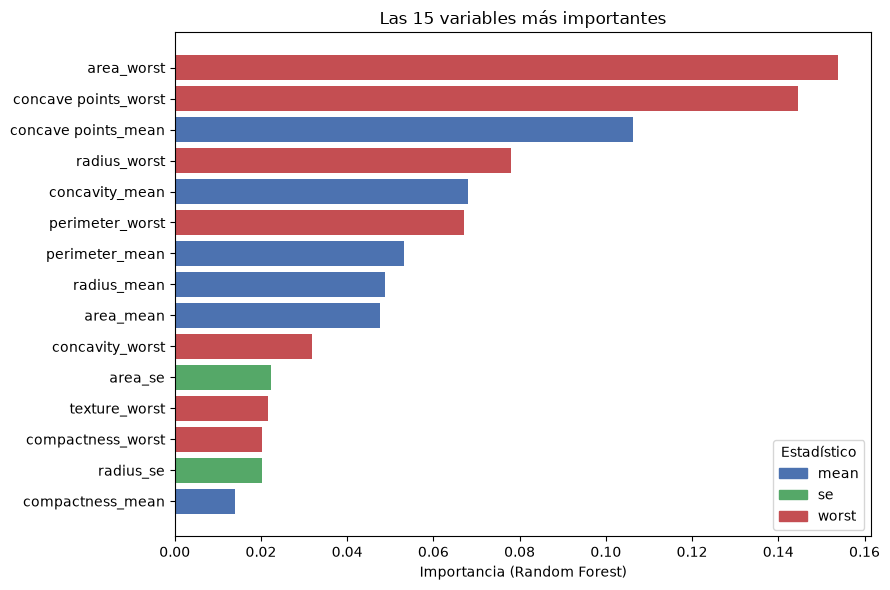

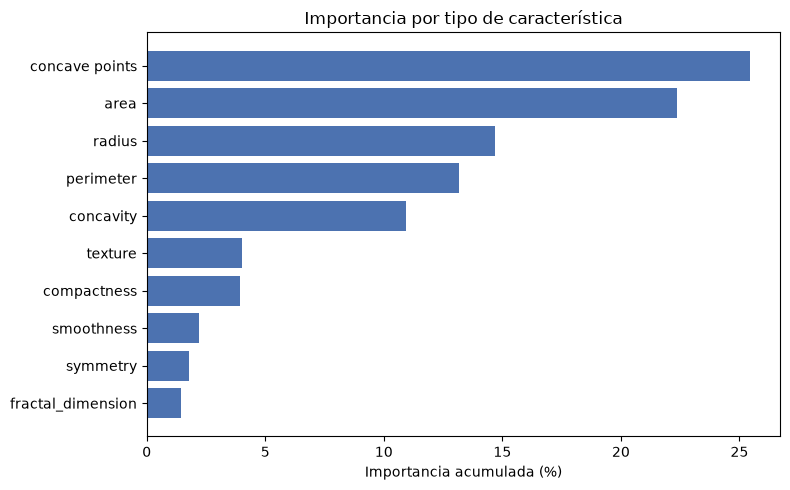

In [10]:
# Grafico las 15 variables más importantes, coloreadas por tipo de estadístico (mean, se, worst).
top15 = importancias["Importancia RF"].head(15).iloc[::-1]
colores = {"mean": "#4C72B0", "se": "#55A868", "worst": "#C44E52"}

plt.figure(figsize=(9, 6))
plt.barh(top15.index, top15.values, color=[colores[n.rsplit("_", 1)[1]] for n in top15.index])
plt.legend(handles=[Patch(color=c, label=e) for e, c in colores.items()], title="Estadístico", loc="lower right")
plt.xlabel("Importancia (Random Forest)")
plt.title("Las 15 variables más importantes")
plt.tight_layout()
plt.savefig("../images/importancia_variables_top15.png", dpi=150, bbox_inches="tight")
plt.show()

# Muchas variables miden lo mismo (por ejemplo radius, perimeter y area), así que también sumo la importancia
# por tipo de característica y por estadístico para tener una lectura menos dispersa.
por_caracteristica = importancias["Importancia RF"].groupby(lambda n: n.rsplit("_", 1)[0]).sum().sort_values(ascending=False)
por_estadistico = importancias["Importancia RF"].groupby(lambda n: n.rsplit("_", 1)[1]).sum().sort_values(ascending=False)

# Grafico la importancia acumulada por tipo de característica.
plt.figure(figsize=(8, 5))
plt.barh(por_caracteristica.index[::-1], por_caracteristica.values[::-1] * 100, color="#4C72B0")
plt.xlabel("Importancia acumulada (%)")
plt.title("Importancia por tipo de característica")
plt.tight_layout()
plt.savefig("../images/importancia_por_caracteristica.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
# Interpretación de los resultados. Calculo las cifras a partir de las tablas anteriores.
top5 = importancias.head(5)
suma_top5 = top5["Importancia RF"].sum() * 100
car5 = por_caracteristica.head(5)
car_resto = por_caracteristica.iloc[5:]
estadisticos = ", ".join(f"`{e}` {v * 100:.0f}%" for e, v in por_estadistico.items())
n_malig = (importancias.head(10)["Valor más alto en"] == "Maligno").sum()
perm_top3 = importancias["Perm. RF (caída AUC)"].sort_values(ascending=False).head(3).index
coinciden = len(set(perm_top3) & set(top5.index))
mejor_auc, peor_auc = auc_individual.idxmax(), auc_individual.idxmin()
v_coef = importancias["Coef. Reg. Logística"].abs().idxmax()
puesto_coef = list(importancias.index).index(v_coef) + 1

display(Markdown("### Interpretación"))
display(Markdown(f"""**¿Cuáles pesan más?** Según el Random Forest, las variables más importantes son {", ".join(f"`{n}`" for n in top5.index)}, que juntas acumulan el {suma_top5:.0f}% de la importancia total. Las tres con mayor importancia por permutación en el conjunto de prueba ({", ".join(f"`{n}`" for n in perm_top3)}) incluyen {coinciden} variables que también están entre las cinco primeras del Random Forest, lo que respalda en general el resultado con datos que el modelo no vio al entrenar.

**Por tipo de característica:** {", ".join(f"`{n}`" for n in car5.index)} acumulan el {car5.sum() * 100:.0f}% de la importancia, mientras que las cinco restantes ({", ".join(f"`{n}`" for n in car_resto.index)}) aportan en conjunto solo el {car_resto.sum() * 100:.0f}%. Por estadístico, la importancia se reparte así: {estadisticos} (`mean` es el promedio, `se` el error estándar y `worst` el promedio de los tres valores más grandes de cada medición).

**Dirección:** en {n_malig} de las 10 variables más importantes, los valores más altos corresponden a tumores malignos (tumores más grandes y con contornos más irregulares). Además, por sí sola `{mejor_auc}` separa las clases con un AUC de {auc_individual.max():.3f}, mientras que `{peor_auc}` ({auc_individual.min():.3f}) prácticamente no las separa.

**Qué tan firme es esta lectura:**
- `radius`, `perimeter` y `area` están correlacionadas por encima de 0.98 (en `mean` y `worst`). Cuando varias variables miden casi lo mismo, los modelos reparten la importancia entre ellas de forma algo arbitraria, así que conviene leer los resultados **por tipo de característica** y no variable por variable.
- Por la misma razón, los coeficientes de la Regresión Logística son menos estables: `{v_coef}` tiene el coeficiente más grande en valor absoluto, pero ocupa el puesto {puesto_coef} en la importancia del Random Forest. Los uso como apoyo y no como ranking definitivo.
- Las caídas de AUC por permutación son pequeñas en valor absoluto porque el modelo ya clasifica casi perfecto y las variables correlacionadas se compensan entre sí al desordenar una sola.
- La importancia describe qué usan los modelos en este dataset, no una relación causal ni un criterio clínico."""))

display(Markdown(f"""### Conclusión sobre la importancia de las variables
La clasificación se apoya sobre todo en el **tamaño del tumor** y en la **forma de su contorno**: {", ".join(f"`{n}`" for n in car5.index)}, en especial en sus valores más extremos (`worst`). Las demás características (textura, suavidad, simetría, dimensión fractal y compacidad) aportan poco según el Random Forest."""))

### Interpretación

**¿Cuáles pesan más?** Según el Random Forest, las variables más importantes son `area_worst`, `concave points_worst`, `concave points_mean`, `radius_worst`, `concavity_mean`, que juntas acumulan el 55% de la importancia total. Las tres con mayor importancia por permutación en el conjunto de prueba (`area_worst`, `concave points_worst`, `perimeter_worst`) incluyen 2 variables que también están entre las cinco primeras del Random Forest, lo que respalda en general el resultado con datos que el modelo no vio al entrenar.

**Por tipo de característica:** `concave points`, `area`, `radius`, `perimeter`, `concavity` acumulan el 87% de la importancia, mientras que las cinco restantes (`texture`, `compactness`, `smoothness`, `symmetry`, `fractal_dimension`) aportan en conjunto solo el 13%. Por estadístico, la importancia se reparte así: `worst` 54%, `mean` 37%, `se` 9% (`mean` es el promedio, `se` el error estándar y `worst` el promedio de los tres valores más grandes de cada medición).

**Dirección:** en 10 de las 10 variables más importantes, los valores más altos corresponden a tumores malignos (tumores más grandes y con contornos más irregulares). Además, por sí sola `perimeter_worst` separa las clases con un AUC de 0.970, mientras que `fractal_dimension_mean` (0.511) prácticamente no las separa.

**Qué tan firme es esta lectura:**
- `radius`, `perimeter` y `area` están correlacionadas por encima de 0.98 (en `mean` y `worst`). Cuando varias variables miden casi lo mismo, los modelos reparten la importancia entre ellas de forma algo arbitraria, así que conviene leer los resultados **por tipo de característica** y no variable por variable.
- Por la misma razón, los coeficientes de la Regresión Logística son menos estables: `texture_worst` tiene el coeficiente más grande en valor absoluto, pero ocupa el puesto 12 en la importancia del Random Forest. Los uso como apoyo y no como ranking definitivo.
- Las caídas de AUC por permutación son pequeñas en valor absoluto porque el modelo ya clasifica casi perfecto y las variables correlacionadas se compensan entre sí al desordenar una sola.
- La importancia describe qué usan los modelos en este dataset, no una relación causal ni un criterio clínico.

### Conclusión sobre la importancia de las variables
La clasificación se apoya sobre todo en el **tamaño del tumor** y en la **forma de su contorno**: `concave points`, `area`, `radius`, `perimeter`, `concavity`, en especial en sus valores más extremos (`worst`). Las demás características (textura, suavidad, simetría, dimensión fractal y compacidad) aportan poco según el Random Forest.

In [12]:
# Respondiendo a las preguntas de la tarea.
display(Markdown("# 🧠 Conclusiones"))
display(Markdown("### Conclusión Comparativa de los Modelos"))
display(Markdown("En este problema de clasificación binaria, la **Regresión Logística** fue el modelo más eficiente, obteniendo mayor precisión y menor número de errores. El Árbol de Decisión mostró **mayor interpretabilidad**, pero con menor rendimiento y más errores. El Random Forest, aunque teóricamente más potente, no presentó mejoras significativas frente al árbol individual, **probablemente debido a la estructura relativamente simple del dataset y al uso de PCA**, lo cual reduce la complejidad de los datos."))

display(Markdown("### ¿Las medidas tomadas inicialmente satisfacieron el modelo? ¿Por qué?"))
display(Markdown("Sí. Las decisiones de preprocesamiento fueron apropiadas porque permitieron que los modelos de clasificación funcionaran de manera eficiente y con buen rendimiento pese a que la Regresión Logística fue más eficiente. En un principio la estandarización de datos fue **necesaria** porque las variables del dataset estaban en escalas diferentes. Se aplicó PCA para reducir la complejidad del dataset y eliminar variables redundantes lo que facilitó la separación de clases. Y el train-test-split entrenó a los modelos con una parte de los datos para evaluar su capacidad de generalización de datos nuevos lo que evita conclusiones sesgadas. Se puede decir que las predicciones fueron satisfactorias porque demuestran un accuracy alto, pocos errores totales y buen balance de precisión y recall."))

display(Markdown("### Conclusión Final."))
display(Markdown("El modelo de **Regresión Logística** fue seleccionado porque logró el mejor equilibrio entre **precisión, estabilidad e interpretabilidad**. Además, en un problema médico como la detección de cáncer, es fundamental minimizar los falsos negativos, y este modelo presentó el menor número de este tipo de errores, lo que lo hace **el más confiable** dentro de los evaluados."))

# 🧠 Conclusiones

### Conclusión Comparativa de los Modelos

En este problema de clasificación binaria, la **Regresión Logística** fue el modelo más eficiente, obteniendo mayor precisión y menor número de errores. El Árbol de Decisión mostró **mayor interpretabilidad**, pero con menor rendimiento y más errores. El Random Forest, aunque teóricamente más potente, no presentó mejoras significativas frente al árbol individual, **probablemente debido a la estructura relativamente simple del dataset y al uso de PCA**, lo cual reduce la complejidad de los datos.

### ¿Las medidas tomadas inicialmente satisfacieron el modelo? ¿Por qué?

Sí. Las decisiones de preprocesamiento fueron apropiadas porque permitieron que los modelos de clasificación funcionaran de manera eficiente y con buen rendimiento pese a que la Regresión Logística fue más eficiente. En un principio la estandarización de datos fue **necesaria** porque las variables del dataset estaban en escalas diferentes. Se aplicó PCA para reducir la complejidad del dataset y eliminar variables redundantes lo que facilitó la separación de clases. Y el train-test-split entrenó a los modelos con una parte de los datos para evaluar su capacidad de generalización de datos nuevos lo que evita conclusiones sesgadas. Se puede decir que las predicciones fueron satisfactorias porque demuestran un accuracy alto, pocos errores totales y buen balance de precisión y recall.

### Conclusión Final.

El modelo de **Regresión Logística** fue seleccionado porque logró el mejor equilibrio entre **precisión, estabilidad e interpretabilidad**. Además, en un problema médico como la detección de cáncer, es fundamental minimizar los falsos negativos, y este modelo presentó el menor número de este tipo de errores, lo que lo hace **el más confiable** dentro de los evaluados.